In [10]:
import numpy as np
import matplotlib.pyplot as plt
import os

# 1. Check if the required data files exist
archivos_listos = True
if not os.path.exists('../simulation/diffusion.dat'):
    print("❌ ERROR: '../simulation/diffusion.dat' not found.")
    archivos_listos = False
if not os.path.exists('../simulation/spectrum.dat'):
    print("❌ ERROR: '../simulation/spectrum.dat' not found.")
    archivos_listos = False

if not archivos_listos:
    print("\n⚠️ Please compile and run your Fortran code first to generate these files.")
else:
    print("✅ Files found. Proceeding to load and plot the data.")

✅ Files found. Proceeding to load and plot the data.


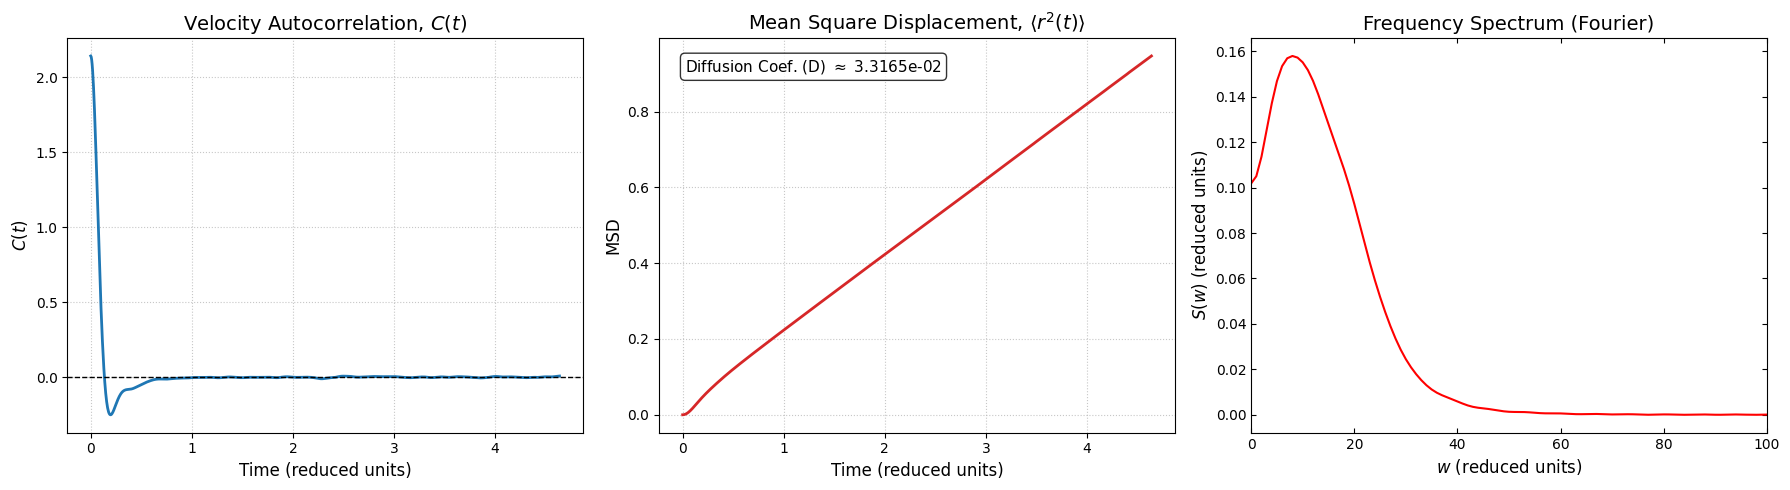

In [ ]:
# Upload the data from the files
data_diff = np.loadtxt('../simulation/diffusion.dat')
time = data_diff[:, 0]
vacf = data_diff[:, 1]
msd = data_diff[:, 2]

data_spec = np.loadtxt('../simulation/spectrum.dat')
w_freq = data_spec[:, 0]
spectrum = data_spec[:, 1]

# 2. Figure style and subplots
plt.style.use('default')
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 5))

# --- Plot 1: Autocorrelation plot ---
ax1.plot(time, vacf, color='#1f77b4', linewidth=2)
ax1.axhline(0, color='black', linestyle='--', linewidth=1) 
ax1.set_title('Velocity Autocorrelation, $C(t)$', fontsize=14)
ax1.set_xlabel('Time (reduced units)', fontsize=12)
ax1.set_ylabel('$C(t)$', fontsize=12)
ax1.grid(True, linestyle=':', alpha=0.7)

# --- Plot 2: Mean Square Displacement r²(t) ---
ax2.plot(time, msd, color='#d62728', linewidth=2)
ax2.set_title('Mean Square Displacement, $\\langle r^2(t) \\rangle$', fontsize=14)
ax2.set_xlabel('Time (reduced units)', fontsize=12)
ax2.set_ylabel('MSD', fontsize=12)
ax2.grid(True, linestyle=':', alpha=0.7)

mitad = len(time) // 2
if mitad > 0:
    pendiente, _ = np.polyfit(time[mitad:], msd[mitad:], 1)
    coef_difusion = pendiente / 6.0
    ax2.text(0.05, 0.95, f'Diffusion Coef. (D) $\\approx$ {coef_difusion:.4e}', 
                transform=ax2.transAxes, fontsize=11, verticalalignment='top', 
                bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

# --- Plot 3: Frequency Spectrum S(w) ---
ax3.plot(w_freq, spectrum, color='red', linewidth=1.5)
ax3.set_title('Frequency Spectrum (Fourier)', fontsize=14)
ax3.set_xlabel('$w$ (reduced units)', fontsize=12)  
ax3.set_ylabel('$S(w)$ (reduced units)', fontsize=12)

# Force x axis limits to be between 0 and 100 for better visualization
ax3.set_xlim(0, 100) 
ax3.tick_params(direction='in', top=True, right=True)

plt.tight_layout()
plt.show()